In [2]:
from pathlib import Path

data_dir = Path("../data/archive/kaggle_3m")
tif_files = list(data_dir.rglob("*.tif"))
len(tif_files)

mask_files = [file for file in tif_files if file.name.endswith("_mask.tif")]
print(len(mask_files))

image_files = [file for file in tif_files if not file.name.endswith("_mask.tif")]
print(len(image_files))

for name in image_files[:3]:
    print(name.name)

image_filename = image_files[0].name
print(image_filename)
mask_filename = mask_files[0].name
print(mask_filename)

first_mask_filename = image_files[0].stem + "_mask.tif"
print(first_mask_filename)

mask_path = image_files[0].with_name(first_mask_filename)
print(mask_path)
print(mask_path.exists())

3929
3929
TCGA_CS_6667_20011105_9.tif
TCGA_CS_6667_20011105_8.tif
TCGA_CS_6667_20011105_16.tif
TCGA_CS_6667_20011105_9.tif
TCGA_CS_6667_20011105_8_mask.tif
TCGA_CS_6667_20011105_9_mask.tif
../data/archive/kaggle_3m/TCGA_CS_6667_20011105/TCGA_CS_6667_20011105_9_mask.tif
True


In [3]:
from PIL import Image

mri_image = Image.open(image_files[0])
print(mri_image.size)

mask_image = Image.open(mask_path)
print(mask_image.size)

(256, 256)
(256, 256)


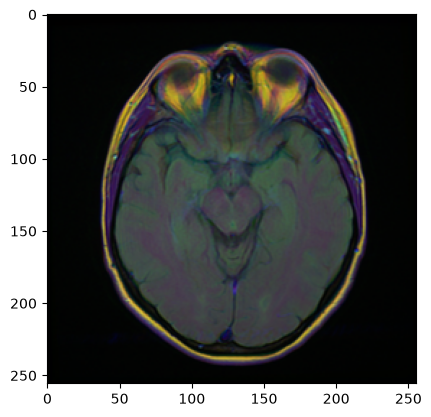

In [4]:
import matplotlib.pyplot as plt
plt.imshow(mri_image)
plt.show()

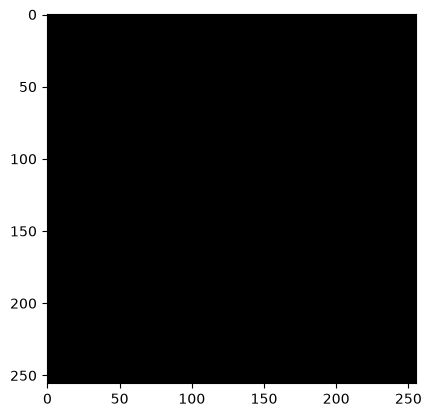

(0, 0)
(0, 0)
TCGA_CS_6667_20011105_15_mask.tif


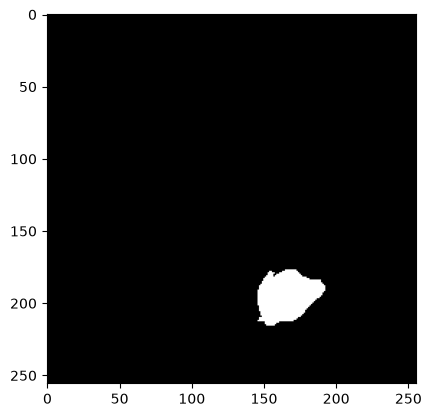

TCGA_CS_6667_20011105_15.tif
True


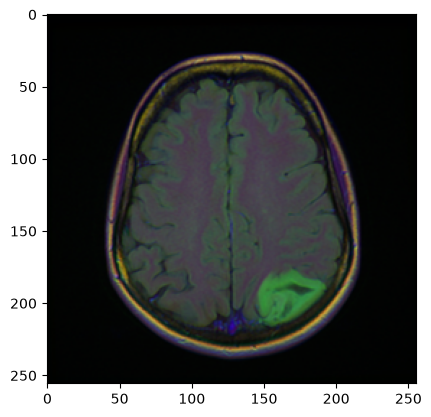

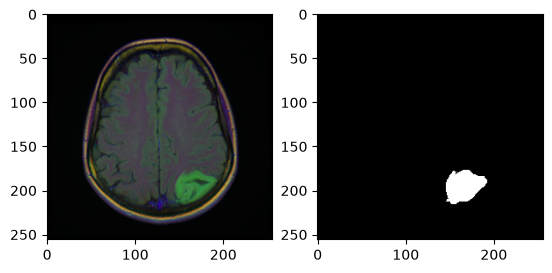

In [15]:
plt.imshow(mask_image,cmap= "gray")
plt.show()
print(mask_image.getextrema())
another_mask = Image.open(mask_files[1])
print(another_mask.getextrema())
for mask_file in mask_files:
    opened_mask = Image.open(mask_file)
    if opened_mask.getextrema()[1] > 0:
        print(mask_file.name)
        break
plt.imshow(opened_mask, cmap= "gray")
plt.show()

matching_image_filename = mask_file.name.replace("_mask.tif", ".tif")
print(matching_image_filename)

matching_image_path = mask_file.with_name(matching_image_filename)
print(matching_image_path.exists())

matching_mri = Image.open(matching_image_path)
plt.imshow(matching_mri)
plt.show()

fig, axes = plt.subplots(1,2)
axes[0].imshow(matching_mri)
axes[1].imshow(opened_mask, cmap = "gray")
plt.show()